# MI / EMSE / Adaptive WIVR Verification

    **Purpose:** verify mathematical scores, exact continuous-route events, adaptive weight lifecycle, cache isolation, and complete GRG recursive dispatch. This is correctness and component-runtime verification, **not a reconstruction-performance ranking**. No RMSE, unseen SRF temperatures or new ROS motion are used.

    The temporary 30 x 30 m rectangle excludes a central 4 x 4 m box. Nine valid 10 m scoring cells have 884 m2 total effective area; a representative inside each valid cell is paired with times 0,0.5,...,120 s (2169 queries). EMSE uses area quadrature. Adaptive WIVR uses area times current latent GP variance, the same spatial importance at every scoring time, and frozen weights throughout one search. Uniform importance per area recovers EMSE.

    Performance cases use the 980 synthetic historical observations and fixed real-data RBF parameters from the preceding test, with 30 or 50 candidate sensing Checkpoints plus Home. Candidates are selected from a 1 m base grid without temperature access. Routes use an explicitly temporary rectangle visibility graph at 1 m/s; actual Nav2 path/timing validation belongs to the next stage.

    The original recursive GRG search is reused unchanged through an adapter. Node dwell is zero; every 1 s event along all legs, including return, is jointly scored. Model equations, query resolution and search settings are unchanged by exact cache/vectorization optimizations.

In [1]:
from pathlib import Path
import csv,json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display,Markdown
ROOT=Path.cwd()
RUN=ROOT/"result"/json.loads((ROOT/"result/latest.json").read_text())["run"]
def read(name):return json.loads((RUN/name).read_text())
summary=read("summary.json");config=read("protocol.json");checks=read("checks.json")
benchmarks=read("search_benchmarks.json");independent=read("independent_route_checks.json")
grid=np.load(RUN/"scoring_grid.npz")
print("Core checks:",sum(c["passed"] for c in checks),"/",len(checks))
print("Independent full-route audits:",sum(c["passed"] for c in independent["rows"]),"/",independent["checks"])
print("Scoring cells / queries:",len(grid["xy"]),len(grid["queries"]),
      "| Effective area:",grid["areas"].sum(),"m2")
print("Full recursive searches:",summary["completed_searches"],"/",summary["requested_searches"])
print("Maximum core numerical error:",summary["maximum_numerical_error"])
print("Maximum independent returned-route gain error:",independent["maximum_absolute_error"])
print("Nominal component+motion arithmetic ready:",summary["performance_ready"])
print("Full ROS mission budget validated:",summary["complete_mission_budget_validated"])
assert summary["passed"] and independent["passed"] and not summary["reconstruction_accuracy_evaluated"]
with (RUN/"mathematical_errors.csv").open() as f:math=list(csv.DictReader(f))
lines=["| Objective | Difference from independent direct formula |",
       "| --- | ---: |"]
for row in math:lines.append(f'| {row["policy"].upper()} | {float(row["absolute_error"]):.3e} |')
display(Markdown(chr(10).join(lines)))
print("Native MI and variance-reduction gains have different meanings/units; their magnitudes are not a policy ranking.")

Core checks: 71 / 71
Independent full-route audits: 6 / 6
Scoring cells / queries: 9 2169 | Effective area: 884.0 m2
Full recursive searches: 6 / 6
Maximum core numerical error: 2.6645352591003757e-15
Maximum independent returned-route gain error: 4.973799150320701e-14
Nominal component+motion arithmetic ready: False
Full ROS mission budget validated: False


| Objective | Difference from independent direct formula |
| --- | ---: |
| MI | 2.665e-15 |
| EMSE | 4.337e-19 |
| WIVR | 5.421e-19 |

Native MI and variance-reduction gains have different meanings/units; their magnitudes are not a policy ranking.


## Effective areas and adaptive spatial importance

    The weight-update pictures below use the **controlled small-GP numerical fixture**, not measured temperatures or a full mission. Importance per unit area equals current variance. The original weight snapshot is immutable; a committed GP update creates a new snapshot. Partial boundary/masked cells, zero-area removal, zero-variance fallback and 5 m-grid area consistency are also checked. This does not complete a reconstruction sensitivity experiment.

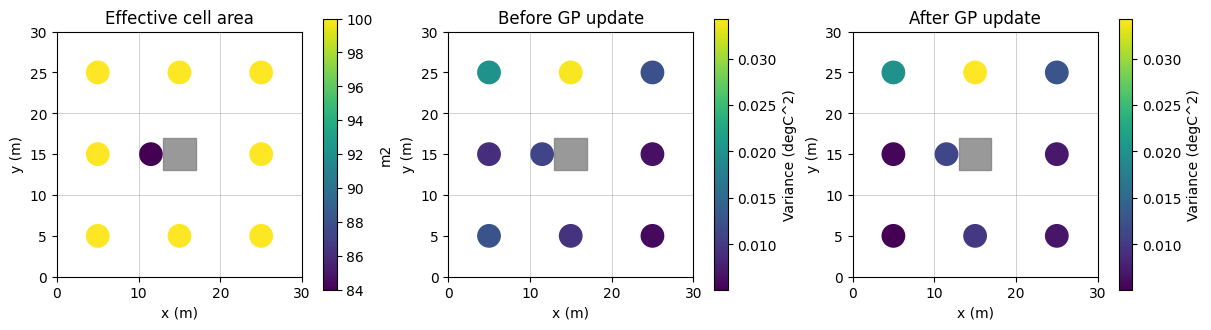

Exact interpolation regression: {'name': 'vectorized_events_match_scalar_reference', 'passed': True, 'cases': 100, 'maximum_absolute_error': 0.0}
Uniform per-area weighting, refreshed weights and every recursive objective dispatch passed.


In [2]:
before=read("weights_initial.json");after=read("weights_updated.json")
fig,axes=plt.subplots(1,3,figsize=(12,3.7),layout="constrained")
arrays=[grid["areas"],np.array(before["spatial_weights"])/grid["areas"],
        np.array(after["spatial_weights"])/grid["areas"]]
titles=["Effective cell area","Before GP update","After GP update"]
for j,(ax,values,title) in enumerate(zip(axes,arrays,titles)):
    bounds={} if j==0 else dict(vmin=min(arrays[1].min(),arrays[2].min()),vmax=max(arrays[1].max(),arrays[2].max()))
    scatter=ax.scatter(grid["xy"][:,0],grid["xy"][:,1],c=values,s=260,cmap="viridis",**bounds)
    for x in [0,10,20,30]:ax.axvline(x,color="gray",lw=.5,alpha=.5);ax.axhline(x,color="gray",lw=.5,alpha=.5)
    ax.add_patch(Rectangle((13,13),4,4,color="gray",alpha=.8))
    ax.set(xlim=(0,30),ylim=(0,30),xlabel="x (m)",ylabel="y (m)",title=title,aspect="equal")
    fig.colorbar(scatter,ax=ax,label="m2" if j==0 else "Variance (degC^2)",shrink=.75)
fig.savefig(RUN/"figures/grid_and_weights.png",dpi=180)
plt.show()
regression=next(c for c in checks if c["name"]=="vectorized_events_match_scalar_reference")
print("Exact interpolation regression:",regression)
print("Uniform per-area weighting, refreshed weights and every recursive objective dispatch passed.")

## Predicted along-route events: functional interface examples

    These are the returned 30-Checkpoint search examples, shown only to inspect the route/event interface. Gray dots are available Checkpoints; crosses are independent scoring representatives; colored dots are predicted 1 Hz measurements. Return motion contributes events. These are geometric fixture predictions, not Gazebo trajectories or evidence that a policy reconstructs better.

MI route: [0, 16, 7, 25, 0] | Along-path events: 99
EMSE route: [0, 16, 7, 11, 0] | Along-path events: 99
WIVR route: [0, 16, 12, 20, 0] | Along-path events: 98


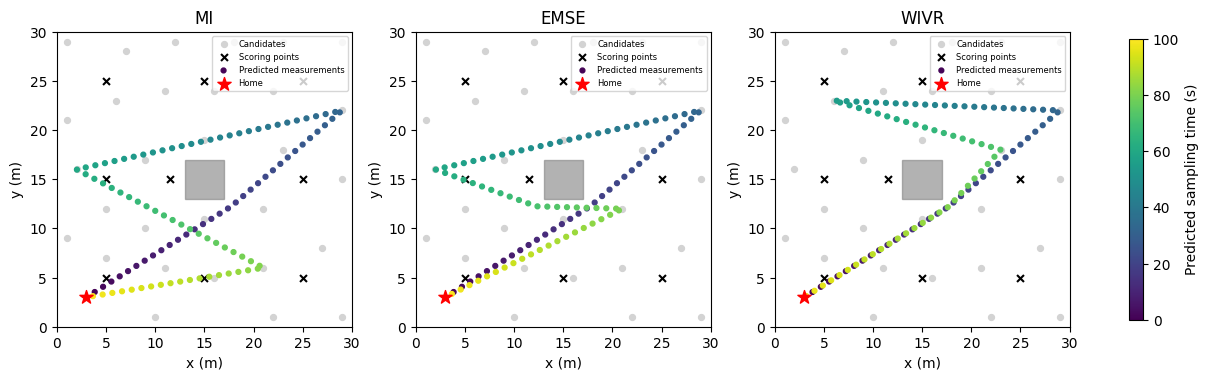

In [3]:
candidates=np.load(RUN/"graph_30.npz")["points"]
fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout="constrained")
for ax,policy in zip(axes,["mi","emse","wivr"]):
    plan=read("plan_30_"+policy+".json");events=np.array(plan["events"])
    ax.scatter(candidates[1:,0],candidates[1:,1],c="lightgray",s=18,label="Candidates")
    ax.scatter(grid["xy"][:,0],grid["xy"][:,1],marker="x",c="black",s=25,label="Scoring points")
    scatter=ax.scatter(events[:,0],events[:,1],c=events[:,2],s=12,cmap="viridis",vmin=0,vmax=100,label="Predicted measurements")
    ax.scatter(*candidates[0],marker="*",s=100,c="red",label="Home")
    ax.add_patch(Rectangle((13,13),4,4,color="gray",alpha=.6))
    ax.set(xlim=(0,30),ylim=(0,30),xlabel="x (m)",ylabel="y (m)",title=policy.upper(),aspect="equal")
    ax.legend(fontsize=6,loc="upper right")
    print(policy.upper(),"route:",plan["route"],"| Along-path events:",len(events))
fig.colorbar(scatter,ax=axes,label="Predicted sampling time (s)",shrink=.8)
fig.savefig(RUN/"figures/continuous_events.png",dpi=180)
plt.show()

## Complete-search computation and budget limitation

    Each policy/count case starts with cold event and score caches, the same GP, grid, geometry, 1 Hz events, depth=2 and two time splits. Times are single-run observations, not replicated statistical estimates.

    The scalar timing attempt remains saved in the previous result directory. Vectorized edge interpolation is checked against it on 100 routes, without changing objectives, event locations/times, cache limits or search settings. Six final-route gains are independently recomputed with the original NumPy GP and uncached direct covariance formulas.

    **Nominal balance = 120 s - one measured planning round - estimated motion.** It excludes actual Nav2 overhead, GP-update costs and later replanning rounds. A positive balance is not full mission acceptance; a negative balance is an immediate budget concern. The 50-Checkpoint EMSE/WIVR cases still exceed this nominal allowance.

| Checkpoints | Policy | Scalar attempt (s) | Current component time (s) | Estimated motion (s) | Nominal balance (s) | Sampled peak RSS (MiB) |
| ---: | --- | ---: | ---: | ---: | ---: | ---: |
| 30 | MI | 8.973 | 2.400 | 99.675 | 17.924 | 127.96 |
| 30 | EMSE | 15.226 | 8.369 | 99.749 | 11.882 | 232.78 |
| 30 | WIVR | 15.206 | 8.437 | 98.236 | 13.327 | 242.41 |
| 50 | MI | 26.500 | 7.315 | 99.675 | 13.009 | 244.17 |
| 50 | EMSE | 43.083 | 24.253 | 99.709 | -3.962 | 245.34 |
| 50 | WIVR | 42.855 | 23.996 | 98.806 | -2.802 | 248.73 |

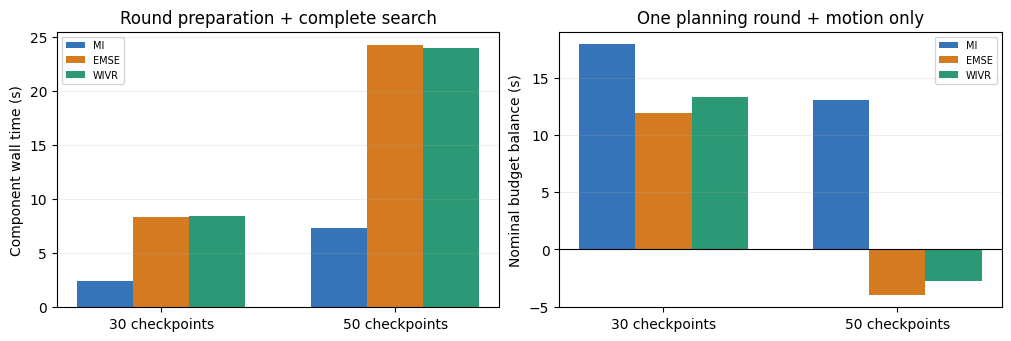

No performance input was downsampled. Scoring time spacing remains 0.5 s; sensing events remain 1 s.


In [4]:
lines=["| Checkpoints | Policy | Scalar attempt (s) | Current component time (s) | Estimated motion (s) | Nominal balance (s) | Sampled peak RSS (MiB) |",
       "| ---: | --- | ---: | ---: | ---: | ---: | ---: |"]
previous_dir=ROOT/"result"/config["previous_timing_run"]
previous=json.loads((previous_dir/"search_benchmarks.json").read_text())
for row in benchmarks:
    old=next(r for r in previous if r["checkpoints"]==row["checkpoints"] and r["policy"]==row["policy"])
    lines.append(f'| {row["checkpoints"]} | {row["policy"].upper()} | {old["total_component_s"]:.3f} | {row["total_component_s"]:.3f} | {row["estimated_motion_s"]:.3f} | {row["nominal_budget_balance_s"]:.3f} | {row["sampled_peak_rss_mib"]:.2f} |')
display(Markdown(chr(10).join(lines)))
fig,axes=plt.subplots(1,2,figsize=(10,3.3),layout="constrained")
colors={"mi":"#3574b9","emse":"#d47b22","wivr":"#2b9975"}
x=np.arange(2);width=.24
for j,policy in enumerate(["mi","emse","wivr"]):
    values=[next(r for r in benchmarks if r["checkpoints"]==n and r["policy"]==policy) for n in [30,50]]
    axes[0].bar(x+(j-1)*width,[r["total_component_s"] for r in values],width,label=policy.upper(),color=colors[policy])
    axes[1].bar(x+(j-1)*width,[r["nominal_budget_balance_s"] for r in values],width,label=policy.upper(),color=colors[policy])
axes[0].set(ylabel="Component wall time (s)",title="Round preparation + complete search")
axes[1].set(ylabel="Nominal budget balance (s)",title="One planning round + motion only")
axes[1].axhline(0,color="black",lw=.8)
for ax in axes:ax.set_xticks(x,["30 checkpoints","50 checkpoints"]);ax.legend(fontsize=7);ax.grid(axis="y",alpha=.2)
fig.savefig(RUN/"figures/search_runtime.png",dpi=180)
plt.show()
print("No performance input was downsampled. Scoring time spacing remains 0.5 s; sensing events remain 1 s.")

## Conclusion

    **Passed:** three mathematical objectives, area correction, variance-based adaptive weighting and fallback, weight freezing, GP/grid/weight/path cache isolation, all recursive target dispatch, continuous return-edge events, all six complete 30/50-Checkpoint searches, and independent final-route gain checks.

    **Open limitation:** 50-Checkpoint EMSE/WIVR computation plus the planned approximately 100 s motion already exceeds the 120 s nominal budget. Start ROS functional integration with the lower-count case and enforce the real budget at each decision; neither case has full mission-time acceptance yet. A mission includes multiple planning rounds, GP updates and actual navigation behavior.

    No reconstruction RMSE, policy superiority or real-field result is claimed. The temporary geometry provider must be replaced by actual Nav2 path/timing inputs for the ROS stage. The original GP/GRG sources, trained parameters and previous-stage files remain unchanged.